# FungiGuard — Analisis dan Pelatihan Model

Fokus notebook: analisis dataset, preprocessing, seleksi fitur, evaluasi, eksperimen sensitivitas, dan ekspor artefak model. **Tidak ada integrasi Streamlit**. Artefak model dapat diintegrasikan ke aplikasi web pada tahap pengembangan berikutnya.

> **Batasan keselamatan:** jangan mengonsumsi jamur liar berdasarkan prediksi model. Evaluasi dataset ini bukan validasi lapangan dan tidak membuktikan kemampuan mengenali spesies jamur baru.


In [1]:
# ============================================================
# CELL 1 - INSTALASI LIBRARY
# ============================================================

!pip install -q ucimlrepo joblib pandas numpy scikit-learn matplotlib seaborn

In [2]:
# ============================================================
# CELL 2 - IMPORT LIBRARIES
# ============================================================

import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import (
    train_test_split,
    RepeatedStratifiedKFold,
    cross_validate
)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.feature_selection import SelectKBest, mutual_info_classif

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

# Folder hasil
os.makedirs("fungiguard_results", exist_ok=True)

print("FungiGuard environment berhasil disiapkan.")
print("Random State:", RANDOM_STATE)

FungiGuard environment berhasil disiapkan.
Random State: 42


In [3]:
# ============================================================
# CELL 3 - LOAD DATASET
# ============================================================

print("=== LOAD UCI MUSHROOM DATASET ===")

mushroom = fetch_ucirepo(id=73)

X_raw = mushroom.data.features.copy()
y_raw = mushroom.data.targets.copy()

# Target encoding
# e = edible = 0
# p = poisonous = 1

y = np.where(
    y_raw.iloc[:, 0].astype(str) == "p",
    1,
    0
)

print("\nDataset berhasil dimuat.")

print("Jumlah baris :", X_raw.shape[0])
print("Jumlah fitur :", X_raw.shape[1])

print("\nDistribusi kelas:")

print(
    pd.Series(y)
    .map({0: "Edible", 1: "Poisonous"})
    .value_counts()
)

print("\nPreview dataset:")

display(X_raw.head())

=== LOAD UCI MUSHROOM DATASET ===

Dataset berhasil dimuat.
Jumlah baris : 8124
Jumlah fitur : 22

Distribusi kelas:
Edible       4208
Poisonous    3916
Name: count, dtype: int64

Preview dataset:


,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,x,s,n,t,p,f,c,n,k,e,...,s,w,w,p,w,o,p,k,s,u
1,x,s,y,t,a,f,c,b,k,e,...,s,w,w,p,w,o,p,n,n,g
2,b,s,w,t,l,f,c,b,n,e,...,s,w,w,p,w,o,p,n,n,m
3,x,y,w,t,p,f,c,n,n,e,...,s,w,w,p,w,o,p,k,s,u
4,x,s,g,f,n,f,w,b,k,t,...,s,w,w,p,w,o,e,n,a,g


=== DATA UNDERSTANDING ===

1. Informasi dataset
Jumlah data: 8124
Jumlah fitur: 22

2. Pemeriksaan duplikasi
Jumlah data duplikat: 0

3. Pemeriksaan missing values


,Missing Values
stalk-root,2480



4. Pemeriksaan fitur konstan
Fitur konstan: ['veil-type']

5. Distribusi target


,Jumlah
Edible,4208
Poisonous,3916


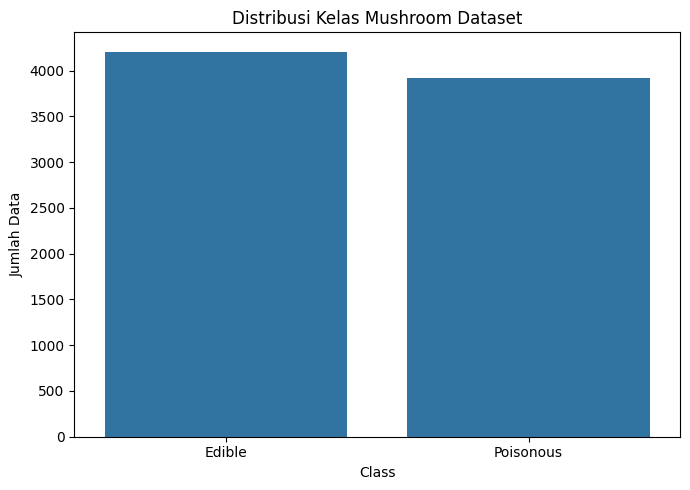

In [4]:
# ============================================================
# CELL 4 - DATA UNDERSTANDING
# ============================================================

print("=== DATA UNDERSTANDING ===")

print("\n1. Informasi dataset")

print("Jumlah data:", X_raw.shape[0])
print("Jumlah fitur:", X_raw.shape[1])

print("\n2. Pemeriksaan duplikasi")

jumlah_duplikat = X_raw.assign(target=y).duplicated().sum()

print("Jumlah data duplikat:", jumlah_duplikat)

print("\n3. Pemeriksaan missing values")

X_check = X_raw.replace("?", np.nan)

missing = X_check.isnull().sum()

display(
    missing[missing > 0].to_frame("Missing Values")
)

print("\n4. Pemeriksaan fitur konstan")

fitur_konstan = [
    col for col in X_raw.columns
    if X_raw[col].nunique(dropna=False) == 1
]

print("Fitur konstan:", fitur_konstan)

print("\n5. Distribusi target")

df_target = pd.Series(y).value_counts().sort_index()

df_target.index = ["Edible", "Poisonous"]

display(df_target.to_frame("Jumlah"))

plt.figure(figsize=(7, 5))

sns.barplot(
    x=df_target.index,
    y=df_target.values
)

plt.title("Distribusi Kelas Mushroom Dataset")
plt.xlabel("Class")
plt.ylabel("Jumlah Data")

plt.tight_layout()
plt.savefig(
    "fungiguard_results/distribusi_target.png",
    dpi=300
)
plt.show()

In [5]:
# ============================================================
# CELL 5 - DATA CLEANING
# ============================================================

print("=== DATA CLEANING ===")

# Mengubah ? menjadi NaN
X_clean = X_raw.replace("?", np.nan).copy()

# Menghapus fitur konstan
X_clean = X_clean.drop(
    columns=fitur_konstan,
    errors="ignore"
)

print("Fitur konstan yang dihapus:", fitur_konstan)

print("\nUkuran dataset setelah cleaning:")

print("Baris :", X_clean.shape[0])
print("Fitur :", X_clean.shape[1])

print("\nMissing values setelah cleaning:")

display(
    X_clean.isnull().sum()[
        X_clean.isnull().sum() > 0
    ].to_frame("Missing Values")
)

print("\nDistribusi target:")

print("0 = Edible")
print("1 = Poisonous")

=== DATA CLEANING ===
Fitur konstan yang dihapus: ['veil-type']

Ukuran dataset setelah cleaning:
Baris : 8124
Fitur : 21

Missing values setelah cleaning:


,Missing Values
stalk-root,2480



Distribusi target:
0 = Edible
1 = Poisonous


In [6]:
# ============================================================
# CELL 6 - DATA SPLITTING
# ============================================================

print("=== DATA SPLITTING 80:20 ===")

X_train, X_test, y_train, y_test = train_test_split(
    X_clean,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Total dataset :", len(X_clean))
print("Training      :", len(X_train))
print("Testing       :", len(X_test))

print("\nDistribusi kelas training:")

display(
    pd.Series(y_train)
    .value_counts()
    .rename(index={0: "Edible", 1: "Poisonous"})
    .to_frame("Jumlah")
)

print("\nDistribusi kelas testing:")

display(
    pd.Series(y_test)
    .value_counts()
    .rename(index={0: "Edible", 1: "Poisonous"})
    .to_frame("Jumlah")
)

=== DATA SPLITTING 80:20 ===
Total dataset : 8124
Training      : 6499
Testing       : 1625

Distribusi kelas training:


,Jumlah
Edible,3366
Poisonous,3133



Distribusi kelas testing:


,Jumlah
Edible,842
Poisonous,783


=== IMPUTATION ===
Modus stalk-root dari training: b
Missing value training setelah imputasi: 0
Missing value testing setelah imputasi: 0

Ranking Mutual Information:


,Fitur,Mutual Information
0,odor,0.627511
1,spore-print-color,0.336772
2,gill-color,0.288473
3,ring-type,0.221329
4,stalk-surface-above-ring,0.200118
5,stalk-surface-below-ring,0.189266
6,stalk-color-above-ring,0.177420
7,stalk-color-below-ring,0.169616
8,gill-size,0.154975
9,population,0.141299



=== 10 FITUR TERPILIH ===
1. odor
2. spore-print-color
3. gill-color
4. ring-type
5. stalk-surface-above-ring
6. stalk-surface-below-ring
7. stalk-color-above-ring
8. stalk-color-below-ring
9. gill-size
10. population


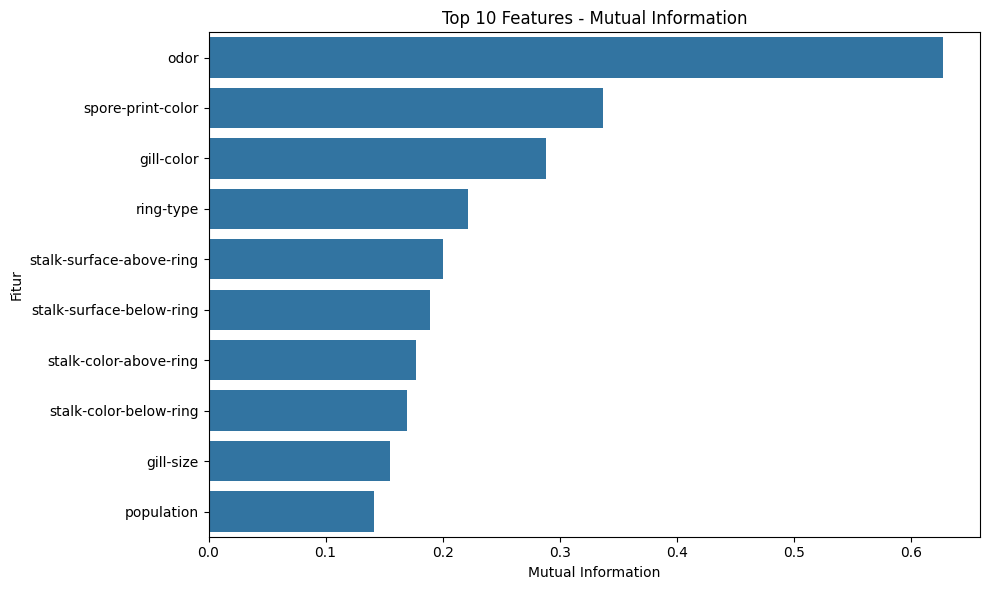

In [7]:
# ============================================================
# CELL 7 - IMPUTATION & MUTUAL INFORMATION
# ============================================================

print("=== IMPUTATION ===")
modus_stalk_root = X_train["stalk-root"].mode()[0]
print("Modus stalk-root dari training:", modus_stalk_root)

X_train_imputed = X_train.copy()
X_test_imputed = X_test.copy()
X_train_imputed["stalk-root"] = X_train_imputed["stalk-root"].fillna(modus_stalk_root)
X_test_imputed["stalk-root"] = X_test_imputed["stalk-root"].fillna(modus_stalk_root)

print("Missing value training setelah imputasi:", X_train_imputed.isnull().sum().sum())
print("Missing value testing setelah imputasi:", X_test_imputed.isnull().sum().sum())

def calculate_mi_dataframe(X, y):
    """MI untuk fitur kategorikal; encoder hanya digunakan pada DataFrame mentah."""
    encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    X_encoded = encoder.fit_transform(X)
    return mutual_info_classif(
        X_encoded, y, discrete_features=True, random_state=RANDOM_STATE
    )

mi_scores = calculate_mi_dataframe(X_train_imputed, y_train)
df_mi = pd.DataFrame({
    "Fitur": X_train_imputed.columns,
    "Mutual Information": mi_scores
}).sort_values("Mutual Information", ascending=False).reset_index(drop=True)

print("\nRanking Mutual Information:")
display(df_mi)

fitur_terpilih = df_mi.head(10)["Fitur"].tolist()
print("\n=== 10 FITUR TERPILIH ===")
for i, fitur in enumerate(fitur_terpilih, 1):
    print(f"{i}. {fitur}")

plt.figure(figsize=(10, 6))
sns.barplot(data=df_mi.head(10), x="Mutual Information", y="Fitur")
plt.title("Top 10 Features - Mutual Information")
plt.tight_layout()
plt.savefig("fungiguard_results/mutual_information.png", dpi=300)
plt.show()


In [8]:
# ============================================================
# CELL 8 - SENSITIVITY ANALYSIS: PENANGANAN STALK-ROOT
# ============================================================

print("=== SENSITIVITY ANALYSIS STALK-ROOT ===")
print("Tiga skenario dibandingkan pada split train-test yang sama.")
print("Seleksi fitur dihitung ulang hanya dari training untuk setiap skenario.")

def make_sensitivity_data(Xtr, Xte, scenario):
    Xtr_s, Xte_s = Xtr.copy(), Xte.copy()
    if scenario == "Mode imputation":
        mode_value = Xtr_s["stalk-root"].mode()[0]
        Xtr_s["stalk-root"] = Xtr_s["stalk-root"].fillna(mode_value)
        Xte_s["stalk-root"] = Xte_s["stalk-root"].fillna(mode_value)
    elif scenario == "Question mark as category":
        Xtr_s["stalk-root"] = Xtr_s["stalk-root"].fillna("?")
        Xte_s["stalk-root"] = Xte_s["stalk-root"].fillna("?")
    elif scenario == "Drop stalk-root":
        Xtr_s = Xtr_s.drop(columns=["stalk-root"])
        Xte_s = Xte_s.drop(columns=["stalk-root"])
    else:
        raise ValueError("Skenario tidak dikenal.")
    return Xtr_s, Xte_s

def select_top_features_from_train(Xtr_s, ytr, k=10):
    Xtr_imp = Xtr_s.copy()
    for col in Xtr_imp.columns:
        if Xtr_imp[col].isna().any():
            Xtr_imp[col] = Xtr_imp[col].fillna(Xtr_imp[col].mode()[0])
    scores = calculate_mi_dataframe(Xtr_imp, ytr)
    return pd.Series(scores, index=Xtr_imp.columns).sort_values(
        ascending=False
    ).head(min(k, len(scores))).index.tolist()

sensitivity_rows = []
for scenario in ["Mode imputation", "Question mark as category", "Drop stalk-root"]:
    Xtr_s, Xte_s = make_sensitivity_data(X_train, X_test, scenario)
    selected_s = select_top_features_from_train(Xtr_s, y_train, k=10)

    sensitivity_model = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
        ("model", RandomForestClassifier(
            n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1
        ))
    ])
    sensitivity_model.fit(Xtr_s[selected_s], y_train)
    pred_s = sensitivity_model.predict(Xte_s[selected_s])
    cm_s = confusion_matrix(y_test, pred_s, labels=[0, 1])

    sensitivity_rows.append({
        "Skenario stalk-root": scenario,
        "Fitur terpilih": ", ".join(selected_s),
        "Jumlah fitur": len(selected_s),
        "Accuracy (%)": round(accuracy_score(y_test, pred_s) * 100, 4),
        "Poisonous predicted edible (FN)": int(cm_s[1, 0]),
        "Edible predicted poisonous (FP)": int(cm_s[0, 1])
    })

df_sensitivity = pd.DataFrame(sensitivity_rows)
display(df_sensitivity)
df_sensitivity.to_csv("fungiguard_results/stalk_root_sensitivity.csv", index=False)

print("\nInterpretasi: cek apakah stalk-root masuk 10 fitur terpilih dan bandingkan FN/FP.")
print("Hasil ini hanya berlaku untuk split dataset ini, bukan validasi lapangan.")


=== SENSITIVITY ANALYSIS STALK-ROOT ===
Tiga skenario dibandingkan pada split train-test yang sama.
Seleksi fitur dihitung ulang hanya dari training untuk setiap skenario.


,Skenario stalk-root,Fitur terpilih,Jumlah fitur,Accuracy (%),Poisonous predicted edible (FN),Edible predicted poisonous (FP)
0,Mode imputation,"odor, spore-print-color, gill-color, ring-type...",10,100.0,0,0
1,Question mark as category,"odor, spore-print-color, gill-color, ring-type...",10,100.0,0,0
2,Drop stalk-root,"odor, spore-print-color, gill-color, ring-type...",10,100.0,0,0



Interpretasi: cek apakah stalk-root masuk 10 fitur terpilih dan bandingkan FN/FP.
Hasil ini hanya berlaku untuk split dataset ini, bukan validasi lapangan.


In [9]:
# ============================================================
# CELL 9 - MODEL COMPARISON & CROSS VALIDATION
# ============================================================

print("=== MODEL COMPARISON ===")


def create_cv_pipeline(model):

    return Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),

        (
            "ordinal",
            OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1
            )
        ),

        (
            "selector",
            SelectKBest(
                score_func=lambda X, y: mutual_info_classif(
                    X, y, discrete_features=True, random_state=RANDOM_STATE
                ),
                k=10
            )
        ),

        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        ),

        ("model", model)
    ])


kandidat_model = {
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),

    "Logistic Regression": LogisticRegression(
        solver="liblinear",
        random_state=RANDOM_STATE,
        max_iter=1000
    )
}


rskf = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=RANDOM_STATE
)

hasil_model = []

for nama, model in kandidat_model.items():

    print(f"\nMengevaluasi: {nama}")

    pipeline = create_cv_pipeline(model)

    hasil_cv = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=rskf,
        scoring="accuracy",
        return_train_score=True,
        n_jobs=-1
    )

    train_acc = hasil_cv["train_score"].mean() * 100
    val_acc = hasil_cv["test_score"].mean() * 100

    gap = train_acc - val_acc

    hasil_model.append({
        "Model": nama,
        "Training Accuracy (%)": round(train_acc, 2),
        "Validation Accuracy (%)": round(val_acc, 2),
        "Gap (%)": round(gap, 2)
    })


df_model = pd.DataFrame(hasil_model)

print("\n=== HASIL PERBANDINGAN MODEL ===")

display(df_model)

df_model.to_csv(
    "fungiguard_results/model_comparison.csv",
    index=False
)

=== MODEL COMPARISON ===

Mengevaluasi: Random Forest

Mengevaluasi: Decision Tree

Mengevaluasi: Logistic Regression

=== HASIL PERBANDINGAN MODEL ===


,Model,Training Accuracy (%),Validation Accuracy (%),Gap (%)
0,Random Forest,100.00,100.00,0.0
1,Decision Tree,100.00,100.00,0.0
2,Logistic Regression,99.92,99.92,0.0


In [10]:
# ============================================================
# CELL 10 - FINAL RANDOM FOREST TRAINING
# ============================================================

print("=== FINAL RANDOM FOREST TRAINING ===")

X_train_final = X_train[fitur_terpilih].copy()
X_test_final = X_test[fitur_terpilih].copy()

pipeline_rf = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),

    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    ),

    (
        "model",
        RandomForestClassifier(
            n_estimators=100,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    )
])

pipeline_rf.fit(
    X_train_final,
    y_train
)

# Memeriksa jumlah fitur hasil encoding
jumlah_fitur_encoded = (
    pipeline_rf
    .named_steps["encoder"]
    .transform(
        pipeline_rf
        .named_steps["imputer"]
        .transform(X_train_final)
    ).shape[1]
)

print("Training selesai.")

print("Data training :", len(X_train_final))
print("Fitur awal    :", X_train_final.shape[1])
print("Fitur encoded :", jumlah_fitur_encoded)

print("\nFitur yang digunakan:")

print(fitur_terpilih)

=== FINAL RANDOM FOREST TRAINING ===
Training selesai.
Data training : 6499
Fitur awal    : 10
Fitur encoded : 69

Fitur yang digunakan:
['odor', 'spore-print-color', 'gill-color', 'ring-type', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring', 'gill-size', 'population']


=== MODEL EVALUATION ===
Accuracy : 100.00%
ROC-AUC  : 1.0000

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

      Edible       1.00      1.00      1.00       842
   Poisonous       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625


=== CONFUSION MATRIX AUDIT ===
True Negative : 842
False Positive: 0
False Negative: 0
True Positive : 783

Jamur beracun yang diprediksi aman: 0


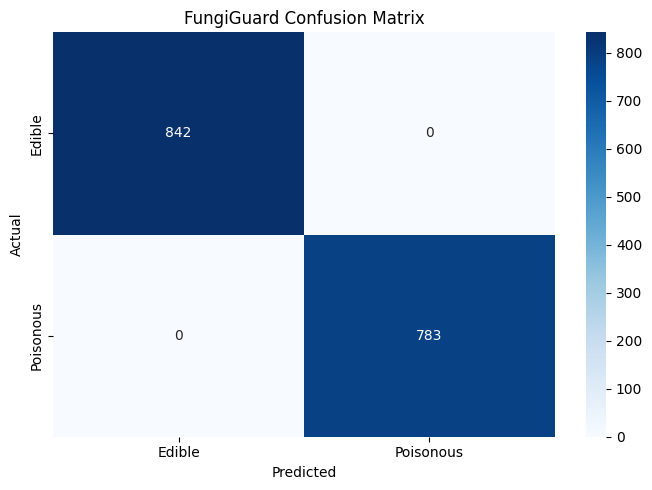

In [11]:
# ============================================================
# CELL 11 - MODEL EVALUATION
# ============================================================

print("=== MODEL EVALUATION ===")

y_pred = pipeline_rf.predict(X_test_final)

y_prob = pipeline_rf.predict_proba(
    X_test_final
)[:, 1]

accuracy = accuracy_score(
    y_test,
    y_pred
)

roc_auc = roc_auc_score(
    y_test,
    y_prob
)

print(f"Accuracy : {accuracy * 100:.2f}%")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\n=== CLASSIFICATION REPORT ===")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Edible",
            "Poisonous"
        ]
    )
)

# Confusion Matrix
cm = confusion_matrix(
    y_test,
    y_pred
)

tn, fp, fn, tp = cm.ravel()

print("\n=== CONFUSION MATRIX AUDIT ===")

print("True Negative :", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive :", tp)

print("\nJamur beracun yang diprediksi aman:", fn)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Edible", "Poisonous"],
    yticklabels=["Edible", "Poisonous"]
)

plt.title("FungiGuard Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()

plt.savefig(
    "fungiguard_results/confusion_matrix.png",
    dpi=300
)

plt.show()

=== PERMUTATION IMPORTANCE ===


,Fitur,Importance,Standard Deviation
0,odor,0.197600,0.008856
8,gill-size,0.057292,0.003107
1,spore-print-color,0.006708,0.000581
9,population,0.003815,0.001285
5,stalk-surface-below-ring,0.001785,0.000431
4,stalk-surface-above-ring,0.001600,0.000564
7,stalk-color-below-ring,0.000123,0.000246
3,ring-type,0.000000,0.000000
2,gill-color,0.000000,0.000000
6,stalk-color-above-ring,0.000000,0.000000


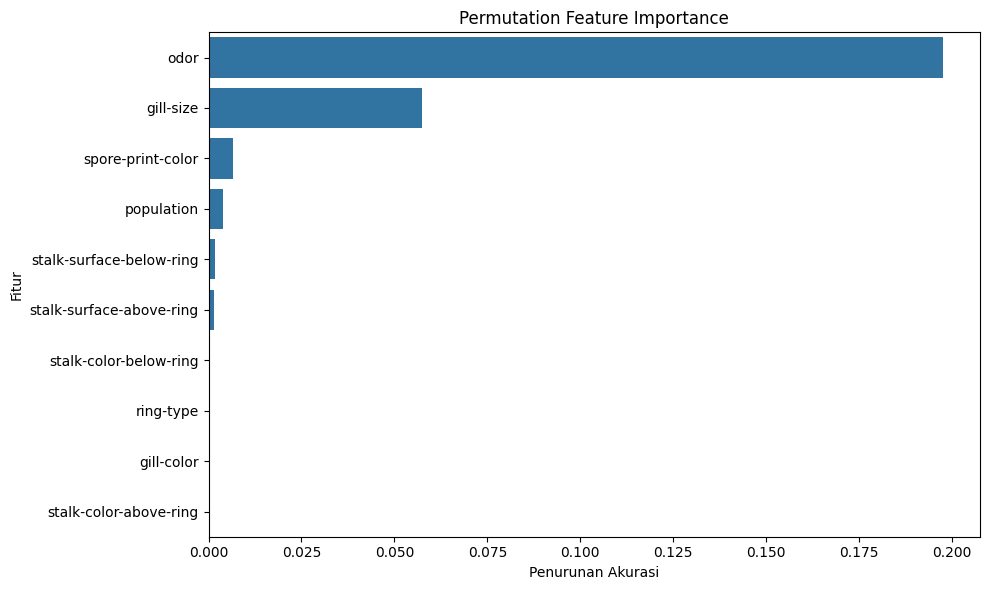

In [12]:
# ============================================================
# CELL 12 - PERMUTATION IMPORTANCE
# ============================================================

print("=== PERMUTATION IMPORTANCE ===")

importance = permutation_importance(
    pipeline_rf,
    X_test_final,
    y_test,
    n_repeats=10,
    random_state=RANDOM_STATE,
    scoring="accuracy",
    n_jobs=-1
)

df_importance = pd.DataFrame({
    "Fitur": fitur_terpilih,

    "Importance": importance.importances_mean,

    "Standard Deviation": importance.importances_std
})

df_importance = df_importance.sort_values(
    by="Importance",
    ascending=False
)

display(df_importance)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=df_importance,
    x="Importance",
    y="Fitur"
)

plt.title("Permutation Feature Importance")

plt.xlabel("Penurunan Akurasi")
plt.ylabel("Fitur")

plt.tight_layout()

plt.savefig(
    "fungiguard_results/permutation_importance.png",
    dpi=300
)

plt.show()

In [13]:
# ============================================================
# CELL 13 - 20 RANDOM SPLIT EXPERIMENTS
# ============================================================

print("=== 20 RANDOM SPLIT EXPERIMENTS ===")

hasil_random_split = []

for seed in range(20):

    X_tr, X_te, y_tr, y_te = train_test_split(
        X_clean,
        y,
        test_size=0.2,
        stratify=y,
        random_state=seed
    )

    # MI dihitung ulang hanya dari training split
    imputer = SimpleImputer(strategy="most_frequent")

    X_tr_imp = pd.DataFrame(
        imputer.fit_transform(X_tr),
        columns=X_tr.columns,
        index=X_tr.index
    )

    encoder = OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )

    X_tr_ord = encoder.fit_transform(X_tr_imp)

    mi = mutual_info_classif(
        X_tr_ord,
        y_tr,
        discrete_features=True,
        random_state=RANDOM_STATE
    )

    selected_indices = np.argsort(mi)[-10:]

    selected_cols = X_tr.columns[selected_indices].tolist()

    # Pipeline final
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),

        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )),

        ("clf", RandomForestClassifier(
            n_estimators=100,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])

    model.fit(
        X_tr[selected_cols],
        y_tr
    )

    pred = model.predict(
        X_te[selected_cols]
    )

    acc = accuracy_score(
        y_te,
        pred
    ) * 100

    cm_split = confusion_matrix(
        y_te,
        pred,
        labels=[0, 1]
    )

    fn_split = cm_split[1, 0]

    hasil_random_split.append({
        "Random State": seed,
        "Accuracy (%)": round(acc, 2),
        "Poisonous Predicted Edible": fn_split
    })


df_random = pd.DataFrame(
    hasil_random_split
)

display(df_random)

print("\nRata-rata akurasi:",
      round(df_random["Accuracy (%)"].mean(), 2), "%")

print("Akurasi minimum:",
      df_random["Accuracy (%)"].min(), "%")

print("Total poisonous lolos:",
      df_random["Poisonous Predicted Edible"].sum())

df_random.to_csv(
    "fungiguard_results/random_split_20.csv",
    index=False
)

=== 20 RANDOM SPLIT EXPERIMENTS ===


,Random State,Accuracy (%),Poisonous Predicted Edible
0,0,100.0,0
1,1,100.0,0
2,2,100.0,0
3,3,100.0,0
4,4,100.0,0
5,5,100.0,0
6,6,100.0,0
7,7,100.0,0
8,8,100.0,0
9,9,100.0,0



Rata-rata akurasi: 100.0 %
Akurasi minimum: 100.0 %
Total poisonous lolos: 0


In [14]:
# ============================================================
# CELL 14 - DATASET STRUCTURE INVESTIGATION
# ============================================================

print("=== DECISION TREE INVESTIGATION ===")

# Decision Tree kedalaman 5
tree_model = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),

    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    )),

    ("tree", DecisionTreeClassifier(
        max_depth=5,
        random_state=RANDOM_STATE
    ))
])

tree_model.fit(
    X_train_final,
    y_train
)

tree_pred = tree_model.predict(
    X_test_final
)

tree_accuracy = accuracy_score(
    y_test,
    tree_pred
)

tree = tree_model.named_steps["tree"]

print("Accuracy:", tree_accuracy * 100, "%")
print("Jumlah daun:", tree.get_n_leaves())
print("Kedalaman:", tree.get_depth())


# Decision Tree kedalaman 3
tree_depth3 = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),

    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    )),

    ("tree", DecisionTreeClassifier(
        max_depth=3,
        random_state=RANDOM_STATE
    ))
])

tree_depth3.fit(
    X_train_final,
    y_train
)

pred_depth3 = tree_depth3.predict(
    X_test_final
)

print("\nAccuracy Decision Tree depth 3:",
      accuracy_score(y_test, pred_depth3) * 100, "%")


# ============================================================
# UNIQUE COMBINATIONS
# ============================================================

print("\n=== UNIQUE FEATURE COMBINATIONS ===")

X_combination = X_clean[fitur_terpilih].copy()

X_combination = X_combination.fillna(
    X_train["stalk-root"].mode()[0]
    if "stalk-root" in X_combination.columns
    else "unknown"
)

df_combination = X_combination.copy()
df_combination["target"] = y

jumlah_kombinasi = (
    df_combination
    .drop_duplicates(subset=fitur_terpilih)
    .shape[0]
)

label_per_combination = (
    df_combination
    .groupby(fitur_terpilih)["target"]
    .nunique()
)

konflik = (
    label_per_combination > 1
).sum()

print("Jumlah kombinasi unik:", jumlah_kombinasi)
print("Kombinasi dengan konflik label:", konflik)


# ============================================================
# ODOR-ONLY ANALYSIS
# ============================================================

print("\n=== ODOR ONLY ANALYSIS ===")

# Menggunakan training untuk membangun aturan odor
odor_train = X_train[["odor"]].copy()
odor_test = X_test[["odor"]].copy()

odor_train["odor"] = odor_train["odor"].fillna(
    odor_train["odor"].mode()[0]
)

odor_test["odor"] = odor_test["odor"].fillna(
    odor_train["odor"].mode()[0]
)

odor_mapping = (
    pd.DataFrame({
        "odor": odor_train["odor"],
        "target": y_train
    })
    .groupby("odor")["target"]
    .agg(lambda x: x.mode()[0])
)

odor_pred = odor_test["odor"].map(
    odor_mapping
)

# Fallback jika ada kategori odor yang tidak pernah muncul
odor_pred = odor_pred.fillna(
    pd.Series(y_train).mode()[0]
).astype(int)

odor_accuracy = accuracy_score(
    y_test,
    odor_pred
)

print("Odor-only accuracy:",
      round(odor_accuracy * 100, 2), "%")

=== DECISION TREE INVESTIGATION ===
Accuracy: 100.0 %
Jumlah daun: 9
Kedalaman: 5

Accuracy Decision Tree depth 3: 99.56923076923077 %

=== UNIQUE FEATURE COMBINATIONS ===
Jumlah kombinasi unik: 531
Kombinasi dengan konflik label: 0

=== ODOR ONLY ANALYSIS ===
Odor-only accuracy: 98.58 %


=== REPEATED SUBSAMPLE LEARNING CURVE ===
Setiap ukuran data diuji dengan 5 seed. Skor testing memakai holdout test yang sama.
Ini analisis tambahan berbasis holdout, bukan learning curve CV formal.


,Jumlah Data,Training Accuracy Mean (%),Training Accuracy Std (%),Testing Accuracy Mean (%),Testing Accuracy Std (%),Poisonous Predicted Edible Mean
0,10,100.0,0.0,90.5477,1.9666,129.6
1,200,100.0,0.0,97.9200,1.1123,28.6
2,800,100.0,0.0,99.8892,0.1011,1.8
3,6499,100.0,0.0,100.0000,0.0000,0.0


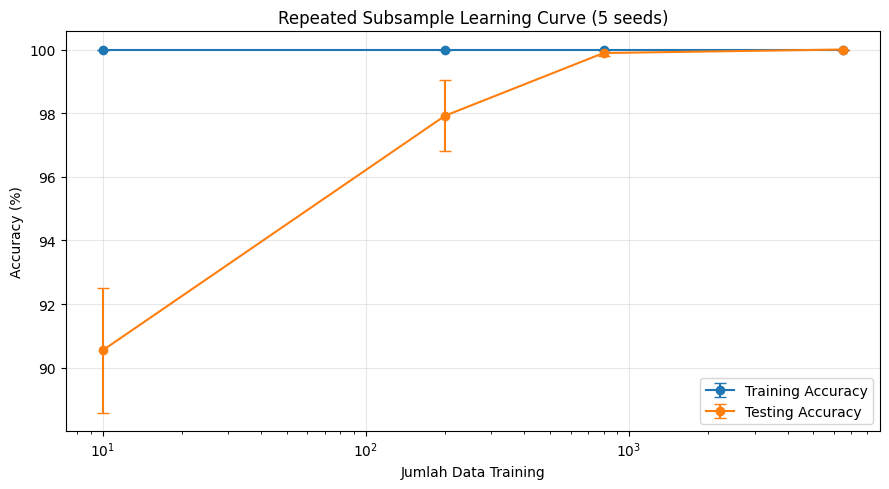

In [15]:
# ============================================================
# CELL 15 - REPEATED SUBSAMPLE LEARNING CURVE
# ============================================================

print("=== REPEATED SUBSAMPLE LEARNING CURVE ===")
print("Setiap ukuran data diuji dengan 5 seed. Skor testing memakai holdout test yang sama.")
print("Ini analisis tambahan berbasis holdout, bukan learning curve CV formal.")

ukuran_data = sorted(set([10, 200, 800, len(X_train)]))
seeds_learning = [11, 22, 33, 44, 55]
hasil_learning = []

for ukuran in ukuran_data:
    for seed in seeds_learning:
        if ukuran == len(X_train):
            X_subset, y_subset = X_train.copy(), y_train.copy()
        else:
            X_subset, _, y_subset, _ = train_test_split(
                X_train, y_train, train_size=ukuran,
                stratify=y_train, random_state=seed
            )

        X_subset_imp = pd.DataFrame(
            SimpleImputer(strategy="most_frequent").fit_transform(X_subset),
            columns=X_subset.columns, index=X_subset.index
        )
        mi_subset = calculate_mi_dataframe(X_subset_imp, y_subset)
        selected_subset = X_subset.columns[np.argsort(mi_subset)[-10:]].tolist()

        learning_model = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore")),
            ("model", RandomForestClassifier(
                n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1
            ))
        ])
        learning_model.fit(X_subset[selected_subset], y_subset)
        train_pred = learning_model.predict(X_subset[selected_subset])
        test_pred = learning_model.predict(X_test[selected_subset])
        test_cm = confusion_matrix(y_test, test_pred, labels=[0, 1])

        hasil_learning.append({
            "Jumlah Data": ukuran,
            "Random Seed": seed,
            "Training Accuracy (%)": accuracy_score(y_subset, train_pred) * 100,
            "Testing Accuracy (%)": accuracy_score(y_test, test_pred) * 100,
            "Poisonous Predicted Edible": int(test_cm[1, 0])
        })

df_learning_runs = pd.DataFrame(hasil_learning)
df_learning = df_learning_runs.groupby("Jumlah Data").agg(
    **{
        "Training Accuracy Mean (%)": ("Training Accuracy (%)", "mean"),
        "Training Accuracy Std (%)": ("Training Accuracy (%)", "std"),
        "Testing Accuracy Mean (%)": ("Testing Accuracy (%)", "mean"),
        "Testing Accuracy Std (%)": ("Testing Accuracy (%)", "std"),
        "Poisonous Predicted Edible Mean": ("Poisonous Predicted Edible", "mean")
    }
).reset_index()

display(df_learning.round(4))

plt.figure(figsize=(9, 5))
plt.errorbar(
    df_learning["Jumlah Data"], df_learning["Training Accuracy Mean (%)"],
    yerr=df_learning["Training Accuracy Std (%)"].fillna(0),
    marker="o", capsize=4, label="Training Accuracy"
)
plt.errorbar(
    df_learning["Jumlah Data"], df_learning["Testing Accuracy Mean (%)"],
    yerr=df_learning["Testing Accuracy Std (%)"].fillna(0),
    marker="o", capsize=4, label="Testing Accuracy"
)
plt.xscale("log")
plt.xlabel("Jumlah Data Training")
plt.ylabel("Accuracy (%)")
plt.title("Repeated Subsample Learning Curve (5 seeds)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("fungiguard_results/learning_curve.png", dpi=300)
plt.show()

df_learning_runs.to_csv("fungiguard_results/learning_curve_runs.csv", index=False)
df_learning.to_csv("fungiguard_results/learning_curve_summary.csv", index=False)


In [16]:
# ============================================================
# CELL 16 - EXPORT MODEL & RESEARCH RESULTS
# ============================================================

print("=== EXPORT FUNGIGUARD ===")

# Simpan pipeline
joblib.dump(
    pipeline_rf,
    "fungiguard_results/fungiguard_final_model.joblib"
)

# Simpan daftar fitur
joblib.dump(
    fitur_terpilih,
    "fungiguard_results/fungiguard_selected_features.joblib"
)

# Simpan hasil eksperimen
df_mi.to_csv(
    "fungiguard_results/mutual_information.csv",
    index=False
)

df_model.to_csv(
    "fungiguard_results/model_comparison.csv",
    index=False
)

df_importance.to_csv(
    "fungiguard_results/permutation_importance.csv",
    index=False
)

df_random.to_csv(
    "fungiguard_results/random_split_20.csv",
    index=False
)

df_learning_runs.to_csv("fungiguard_results/learning_curve_runs.csv", index=False)
df_learning.to_csv("fungiguard_results/learning_curve_summary.csv", index=False)
df_sensitivity.to_csv("fungiguard_results/stalk_root_sensitivity.csv", index=False)

# Simpan metadata
metadata = {
    "project": "FungiGuard",
    "dataset": "UCI Mushroom Dataset",
    "uci_id": 73,
    "target_mapping": {
        "edible": 0,
        "poisonous": 1
    },
    "random_state": RANDOM_STATE,
    "test_size": 0.2,
    "selected_features": fitur_terpilih,
    "model": "RandomForestClassifier",
    "n_estimators": 100,
    "encoding": "OneHotEncoder",
    "imputation": "most_frequent",
"safety_note": "Jangan mengonsumsi jamur liar berdasarkan prediksi model.",
"validation_scope": "Evaluasi internal pada UCI Mushroom Dataset; bukan validasi lapangan atau bukti generalisasi ke spesies baru."
}

joblib.dump(
    metadata,
    "fungiguard_results/fungiguard_metadata.joblib"
)

print("\nExport berhasil.")

print("Model      : fungiguard_final_model.joblib")
print("Fitur      : fungiguard_selected_features.joblib")
print("Metadata   : fungiguard_metadata.joblib")

# Zip seluruh hasil
import shutil

shutil.make_archive(
    "FungiGuard_Final_Results",
    "zip",
    "fungiguard_results"
)

print("\nSeluruh hasil berhasil dikompres.")

from google.colab import files

files.download(
    "FungiGuard_Final_Results.zip"
)

=== EXPORT FUNGIGUARD ===

Export berhasil.
Model      : fungiguard_final_model.joblib
Fitur      : fungiguard_selected_features.joblib
Metadata   : fungiguard_metadata.joblib

Seluruh hasil berhasil dikompres.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>